In [1]:
import os, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110, "axes.titleweight": "bold"})

# Rutas relativas a la raíz del repo (notebooks/01_eda/ -> ../../)
ROOT = Path(os.environ.get("OLIST_ROOT", Path.cwd().parents[1] if Path.cwd().name == "01_eda" else Path.cwd()))
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"
DOCS = ROOT / "docs"
for p in (RAW, FIG): p.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

HALLAZGOS = {}  # métricas clave para la presentación
print("ROOT:", ROOT.resolve())

ROOT: /home/claude/olist


## 1. Carga del dataset

In [2]:
FILES = {
    "customers":    "olist_customers_dataset.csv",
    "geolocation":  "olist_geolocation_dataset.csv",
    "orders":       "olist_orders_dataset.csv",
    "order_items":  "olist_order_items_dataset.csv",
    "payments":     "olist_order_payments_dataset.csv",
    "reviews":      "olist_order_reviews_dataset.csv",
    "products":     "olist_products_dataset.csv",
    "sellers":      "olist_sellers_dataset.csv",
    "category_tr":  "product_category_name_translation.csv",
}

def resolve_data_dir():
    if all((RAW / f).exists() for f in FILES.values()):
        return RAW
    import kagglehub
    path = Path(kagglehub.dataset_download("olistbr/brazilian-ecommerce"))
    # copia a data/raw para reproducibilidad
    import shutil
    for f in FILES.values():
        if not (RAW / f).exists():
            shutil.copy(path / f, RAW / f)
    return RAW

DATA = resolve_data_dir()
dfs = {k: pd.read_csv(DATA / f, encoding="utf-8-sig") for k, f in FILES.items()}

resumen = pd.DataFrame({
    "tabla": list(dfs),
    "archivo": list(FILES.values()),
    "filas": [len(d) for d in dfs.values()],
    "columnas": [d.shape[1] for d in dfs.values()],
    "MB_memoria": [d.memory_usage(deep=True).sum() / 1e6 for d in dfs.values()],
})
HALLAZGOS["tablas"] = resumen.set_index("tabla")[["filas", "columnas"]].to_dict("index")
resumen

,tabla,archivo,filas,columnas,MB_memoria
0,customers,olist_customers_dataset.csv,99441,5,27.88
1,geolocation,olist_geolocation_dataset.csv,1000163,5,135.67
2,orders,olist_orders_dataset.csv,99441,8,55.51
3,order_items,olist_order_items_dataset.csv,112650,7,37.74
4,payments,olist_order_payments_dataset.csv,103886,5,17.02
5,reviews,olist_order_reviews_dataset.csv,99224,7,41.03
6,products,olist_products_dataset.csv,32951,9,6.60
7,sellers,olist_sellers_dataset.csv,3095,4,0.62
8,category_tr,product_category_name_translation.csv,71,2,0.01


In [3]:
# Conversión de fechas
date_cols = {
    "orders": ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date", "order_estimated_delivery_date"],
    "order_items": ["shipping_limit_date"],
    "reviews": ["review_creation_date", "review_answer_timestamp"],
}
for t, cols in date_cols.items():
    for c in cols:
        dfs[t][c] = pd.to_datetime(dfs[t][c], errors="coerce")

o = dfs["orders"]
print("Periodo:", o.order_purchase_timestamp.min(), "→", o.order_purchase_timestamp.max())
HALLAZGOS["periodo"] = [str(o.order_purchase_timestamp.min().date()), str(o.order_purchase_timestamp.max().date())]

Periodo: 2016-09-04 21:15:19 → 2018-10-17 17:30:18


## 2. Diccionario de datos
Se genera automáticamente (tipo, % nulos, únicos, ejemplo) y se completa con la descripción de negocio.
Se exporta a `docs/diccionario_datos.xlsx` para pegarlo en el informe.

In [4]:
DESC = {
 "customer_id": "ID del cliente por pedido (cambia en cada compra). Llave hacia orders",
 "customer_unique_id": "ID real del cliente (persona). Usar para RFM y recompras",
 "customer_zip_code_prefix": "5 primeros dígitos del código postal del cliente",
 "customer_city": "Ciudad del cliente", "customer_state": "Estado (UF) del cliente",
 "geolocation_zip_code_prefix": "Prefijo de código postal", "geolocation_lat": "Latitud",
 "geolocation_lng": "Longitud", "geolocation_city": "Ciudad", "geolocation_state": "Estado (UF)",
 "order_id": "ID único del pedido (PK de orders)",
 "order_status": "Estado del pedido (delivered, shipped, canceled, ...)",
 "order_purchase_timestamp": "Fecha y hora de compra",
 "order_approved_at": "Fecha de aprobación del pago",
 "order_delivered_carrier_date": "Fecha de entrega al operador logístico",
 "order_delivered_customer_date": "Fecha real de entrega al cliente",
 "order_estimated_delivery_date": "Fecha estimada de entrega informada al cliente",
 "order_item_id": "Número secuencial del ítem dentro del pedido",
 "product_id": "ID único del producto", "seller_id": "ID único del vendedor",
 "shipping_limit_date": "Fecha límite para que el vendedor despache",
 "price": "Precio del ítem (BRL)", "freight_value": "Costo de flete del ítem (BRL)",
 "payment_sequential": "Secuencia del medio de pago (un pedido puede tener varios)",
 "payment_type": "Medio de pago (credit_card, boleto, voucher, debit_card)",
 "payment_installments": "Número de cuotas", "payment_value": "Monto pagado (BRL)",
 "review_id": "ID de la reseña", "review_score": "Calificación 1–5 (variable objetivo de clasificación)",
 "review_comment_title": "Título del comentario (portugués)",
 "review_comment_message": "Texto del comentario (portugués) — insumo de minería de textos",
 "review_creation_date": "Fecha de envío de la encuesta de satisfacción",
 "review_answer_timestamp": "Fecha de respuesta de la encuesta",
 "product_category_name": "Categoría del producto (portugués)",
 "product_name_lenght": "Longitud del nombre del producto (caracteres)",
 "product_description_lenght": "Longitud de la descripción (caracteres)",
 "product_photos_qty": "Número de fotos publicadas",
 "product_weight_g": "Peso (g)", "product_length_cm": "Largo (cm)",
 "product_height_cm": "Alto (cm)", "product_width_cm": "Ancho (cm)",
 "seller_zip_code_prefix": "Prefijo postal del vendedor", "seller_city": "Ciudad del vendedor",
 "seller_state": "Estado (UF) del vendedor",
 "product_category_name_english": "Categoría traducida al inglés",
}
PK = {"customers": "customer_id", "orders": "order_id", "products": "product_id",
      "sellers": "seller_id", "category_tr": "product_category_name"}

rows = []
for t, d in dfs.items():
    for c in d.columns:
        s = d[c]
        ej = s.dropna().iloc[0] if s.notna().any() else None
        rows.append({
            "tabla": t, "variable": c, "tipo": str(s.dtype),
            "rol": "PK" if PK.get(t) == c else ("FK" if c.endswith("_id") else ""),
            "descripcion": DESC.get(c, ""),
            "%_nulos": round(s.isna().mean() * 100, 2),
            "n_unicos": s.nunique(),
            "ejemplo": str(ej)[:40],
        })
diccionario = pd.DataFrame(rows)
diccionario.to_excel(DOCS / "diccionario_datos.xlsx", index=False)
diccionario

,tabla,variable,tipo,rol,descripcion,%_nulos,n_unicos,ejemplo
0,customers,customer_id,str,PK,ID del cliente por pedido (cambia en cada comp...,0.00,99441,06b8999e2fba1a1fbc88172c00ba8bc7
1,customers,customer_unique_id,str,FK,ID real del cliente (persona). Usar para RFM y...,0.00,96096,861eff4711a542e4b93843c6dd7febb0
2,customers,customer_zip_code_prefix,int64,,5 primeros dígitos del código postal del cliente,0.00,14995,14409
3,customers,customer_city,str,,Ciudad del cliente,0.00,4119,franca
4,customers,customer_state,str,,Estado (UF) del cliente,0.00,27,SP
5,geolocation,geolocation_zip_code_prefix,int64,,Prefijo de código postal,0.00,19015,1037
6,geolocation,geolocation_lat,float64,,Latitud,0.00,717360,-23.54562128115268
7,geolocation,geolocation_lng,float64,,Longitud,0.00,717613,-46.63929204800168
8,geolocation,geolocation_city,str,,Ciudad,0.00,8011,sao paulo
9,geolocation,geolocation_state,str,,Estado (UF),0.00,27,SP


## 3. Integración de fuentes (dataset a nivel pedido)
Modelo relacional de Olist: `customers 1—N orders 1—N order_items N—1 products / sellers`, y `orders 1—N payments / reviews`.
Se construye una tabla maestra por `order_id` con variables derivadas (feature engineering inicial).

In [5]:
c, o, it, pay, rev, prod, sel, tr = (dfs[k] for k in
    ["customers", "orders", "order_items", "payments", "reviews", "products", "sellers", "category_tr"])

prod = prod.merge(tr, on="product_category_name", how="left")
prod["category"] = prod["product_category_name_english"].fillna(prod["product_category_name"]).fillna("sin_categoria")

items_full = it.merge(prod[["product_id", "category", "product_weight_g"]], on="product_id", how="left") \
               .merge(sel[["seller_id", "seller_state"]], on="seller_id", how="left")

items_agg = items_full.groupby("order_id").agg(
    n_items=("order_item_id", "count"), n_productos=("product_id", "nunique"),
    n_sellers=("seller_id", "nunique"), n_categorias=("category", "nunique"),
    price_total=("price", "sum"), freight_total=("freight_value", "sum"),
    peso_total_g=("product_weight_g", "sum"),
    categoria_principal=("category", "first"), seller_state=("seller_state", "first"),
).reset_index()

pay_agg = pay.groupby("order_id").agg(
    payment_value=("payment_value", "sum"), n_cuotas=("payment_installments", "max"),
    payment_type=("payment_type", lambda s: s.mode().iat[0]),
).reset_index()

# Una reseña por pedido (la más reciente)
rev_1 = rev.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")

df = (o.merge(c, on="customer_id", how="left")
        .merge(items_agg, on="order_id", how="left")
        .merge(pay_agg, on="order_id", how="left")
        .merge(rev_1[["order_id", "review_score", "review_comment_message"]], on="order_id", how="left"))

# Variables derivadas
df["dias_entrega"] = (df.order_delivered_customer_date - df.order_purchase_timestamp).dt.total_seconds() / 86400
df["dias_estimados"] = (df.order_estimated_delivery_date - df.order_purchase_timestamp).dt.total_seconds() / 86400
df["dias_retraso"] = (df.order_delivered_customer_date - df.order_estimated_delivery_date).dt.total_seconds() / 86400
df["entrega_tardia"] = (df.dias_retraso > 0).astype(int).where(df.order_delivered_customer_date.notna())
df["mismo_estado"] = (df.customer_state == df.seller_state).astype(int)
df["ratio_flete"] = df.freight_total / df.price_total
df["tiene_comentario"] = df.review_comment_message.notna().astype(int)
df["review_negativa"] = (df.review_score <= 2).astype(int).where(df.review_score.notna())
df["mes"] = df.order_purchase_timestamp.dt.to_period("M")

print(df.shape)
df.head()

(99441, 35)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,n_items,n_productos,n_sellers,n_categorias,price_total,freight_total,peso_total_g,categoria_principal,seller_state,payment_value,n_cuotas,payment_type,review_score,review_comment_message,dias_entrega,dias_estimados,dias_retraso,entrega_tardia,mismo_estado,ratio_flete,tiene_comentario,review_negativa,mes
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.00,1.00,1.00,1.00,29.99,8.72,500.00,housewares,SP,38.71,1.00,voucher,4.00,"Não testei o produto ainda, mas ele veio corre...",8.44,15.54,-7.11,0.00,1,0.29,1,0.00,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.00,1.00,1.00,1.00,118.70,22.76,400.00,perfumery,SP,141.46,1.00,boleto,4.00,Muito bom o produto.,13.78,19.14,-5.36,0.00,0,0.19,1,0.00,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.00,1.00,1.00,1.00,159.90,19.22,420.00,auto,SP,179.12,3.00,credit_card,5.00,NaN,9.39,26.64,-17.25,0.00,0,0.12,0,0.00,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1.00,1.00,1.00,1.00,45.00,27.20,450.00,pet_shop,MG,72.20,1.00,credit_card,5.00,O produto foi exatamente o que eu esperava e e...,13.21,26.19,-12.98,0.00,0,0.60,1,0.00,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1.00,1.00,1.00,1.00,19.90,8.72,250.00,stationery,SP,28.62,1.00,credit_card,5.00,NaN,2.87,12.11,-9.24,0.00,1,0.44,0,0.00,2018-02


## 4. Calidad de datos

### 4.1 Valores faltantes

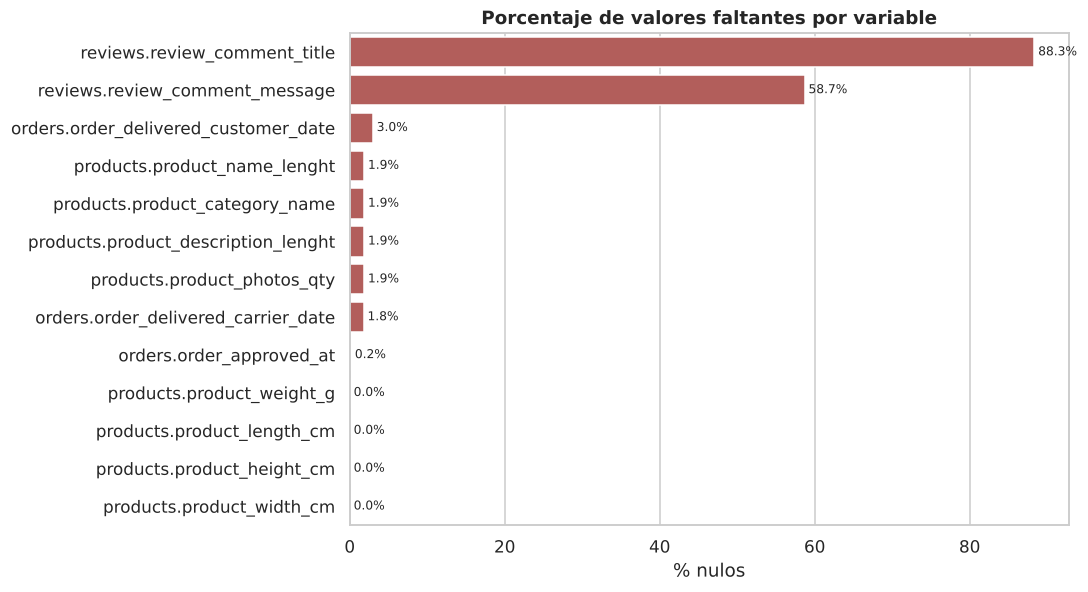

,tabla,variable,%_nulos
33,reviews,review_comment_title,88.34
34,reviews,review_comment_message,58.70
16,orders,order_delivered_customer_date,2.98
39,products,product_name_lenght,1.85
38,products,product_category_name,1.85
40,products,product_description_lenght,1.85
41,products,product_photos_qty,1.85
15,orders,order_delivered_carrier_date,1.79
14,orders,order_approved_at,0.16
42,products,product_weight_g,0.01


In [6]:
nulos = (pd.concat({t: d.isna().mean() * 100 for t, d in dfs.items()})
           .rename("%_nulos").reset_index().rename(columns={"level_0": "tabla", "level_1": "variable"}))
nulos = nulos[nulos["%_nulos"] > 0].sort_values("%_nulos", ascending=False)
HALLAZGOS["nulos"] = {f"{r.tabla}.{r.variable}": round(r["%_nulos"], 2) for _, r in nulos.iterrows()}

fig, ax = plt.subplots(figsize=(10, 0.35 * len(nulos) + 1))
sns.barplot(data=nulos, y=nulos.tabla + "." + nulos.variable, x="%_nulos", ax=ax, color="#c0504d")
ax.set(title="Porcentaje de valores faltantes por variable", xlabel="% nulos", ylabel="")
for p in ax.patches: ax.text(p.get_width() + 0.5, p.get_y() + p.get_height() / 2, f"{p.get_width():.1f}%", va="center", fontsize=8)
savefig("q01_nulos")
nulos

In [7]:
# ¿Los nulos de fechas de entrega son explicables por el estado del pedido?
pd.crosstab(o.order_status, o.order_delivered_customer_date.isna(), margins=True,
            colnames=["sin fecha de entrega"])

sin fecha de entrega,False,True,All
order_status,,,
approved,0,2,2
canceled,6,619,625
created,0,5,5
delivered,96470,8,96478
invoiced,0,314,314
processing,0,301,301
shipped,0,1107,1107
unavailable,0,609,609
All,96476,2965,99441


### 4.2 Registros duplicados

In [8]:
dups = {
    "orders (order_id)": o.order_id.duplicated().sum(),
    "customers (customer_id)": c.customer_id.duplicated().sum(),
    "reviews (review_id)": rev.review_id.duplicated().sum(),
    "reviews: pedidos con >1 reseña": (rev.order_id.value_counts() > 1).sum(),
    "geolocation: filas exactamente duplicadas": dfs["geolocation"].duplicated().sum(),
    "products (product_id)": prod.product_id.duplicated().sum(),
}
HALLAZGOS["duplicados"] = {k: int(v) for k, v in dups.items()}
pd.Series(dups, name="n_duplicados").to_frame()

,n_duplicados
orders (order_id),0
customers (customer_id),0
reviews (review_id),814
reviews: pedidos con >1 reseña,547
geolocation: filas exactamente duplicadas,261831
products (product_id),0


### 4.3 Valores inconsistentes

In [9]:
inc = {
    "entrega antes de la compra": (o.order_delivered_customer_date < o.order_purchase_timestamp).sum(),
    "aprobación antes de la compra": (o.order_approved_at < o.order_purchase_timestamp).sum(),
    "entrega a cliente antes que al transportista": (o.order_delivered_customer_date < o.order_delivered_carrier_date).sum(),
    "transportista antes de aprobación": (o.order_delivered_carrier_date < o.order_approved_at).sum(),
    "status 'delivered' sin fecha de entrega": ((o.order_status == "delivered") & o.order_delivered_customer_date.isna()).sum(),
    "status 'canceled' con fecha de entrega": ((o.order_status == "canceled") & o.order_delivered_customer_date.notna()).sum(),
    "pedidos sin ítems": (~o.order_id.isin(it.order_id)).sum(),
    "pedidos sin pago": (~o.order_id.isin(pay.order_id)).sum(),
    "pagos con valor 0": (pay.payment_value == 0).sum(),
    "productos sin categoría": prod.product_category_name.isna().sum(),
    "categorías sin traducción": prod.loc[prod.product_category_name.notna() & prod.product_category_name_english.isna(), "product_category_name"].nunique(),
    "pago total ≠ precio+flete (>1 BRL)": ((df.payment_value - (df.price_total + df.freight_total)).abs() > 1).sum(),
}
HALLAZGOS["inconsistencias"] = {k: int(v) for k, v in inc.items()}
pd.Series(inc, name="n_registros").to_frame()

,n_registros
entrega antes de la compra,0
aprobación antes de la compra,0
entrega a cliente antes que al transportista,23
transportista antes de aprobación,1359
status 'delivered' sin fecha de entrega,8
status 'canceled' con fecha de entrega,6
pedidos sin ítems,775
pedidos sin pago,1
pagos con valor 0,9
productos sin categoría,610


### 4.4 Outliers (IQR y Z-Score)

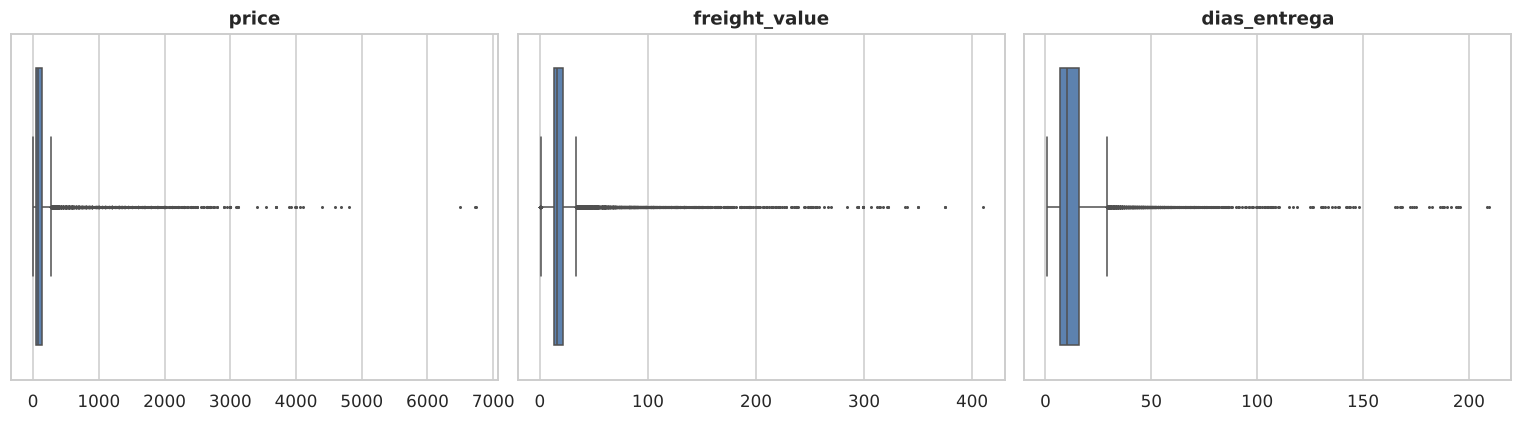

,variable,n,media,mediana,max,limite_sup_IQR,outliers_IQR,%_IQR,outliers_Z>3
0,price,112650,120.65,74.99,"6,735.00",277.40,8427,7.48,1966
1,freight_value,112650,20.03,16.27,409.68,33.25,12180,10.81,1982
2,payment_value,103886,154.10,100.00,"13,664.08",344.41,7981,7.68,1803
3,product_weight_g,32949,"2,276.47",700.00,"40,425.00","4,300.00",4551,13.81,961
4,dias_entrega,96476,12.56,10.22,209.63,29.15,4899,5.08,1571


In [10]:
def outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum(), q3 + 1.5 * iqr

vars_num = {"price": it.price, "freight_value": it.freight_value, "payment_value": pay.payment_value,
            "product_weight_g": prod.product_weight_g, "dias_entrega": df.dias_entrega}
out = []
for k, s in vars_num.items():
    s = s.dropna(); n, lim = outliers_iqr(s)
    z = ((s - s.mean()) / s.std()).abs()
    out.append({"variable": k, "n": len(s), "media": s.mean(), "mediana": s.median(), "max": s.max(),
                "limite_sup_IQR": lim, "outliers_IQR": n, "%_IQR": n / len(s) * 100, "outliers_Z>3": (z > 3).sum()})
outl = pd.DataFrame(out)
HALLAZGOS["outliers"] = outl.set_index("variable")[["outliers_IQR", "%_IQR"]].round(2).to_dict("index")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (k, s) in zip(axes, [("price", it.price), ("freight_value", it.freight_value), ("dias_entrega", df.dias_entrega)]):
    sns.boxplot(x=s.dropna(), ax=ax, color="#4f81bd", fliersize=1)
    ax.set(title=k, xlabel="")
savefig("q02_boxplots_outliers")
outl

### 4.5 Desbalance de la variable objetivo (review_score)

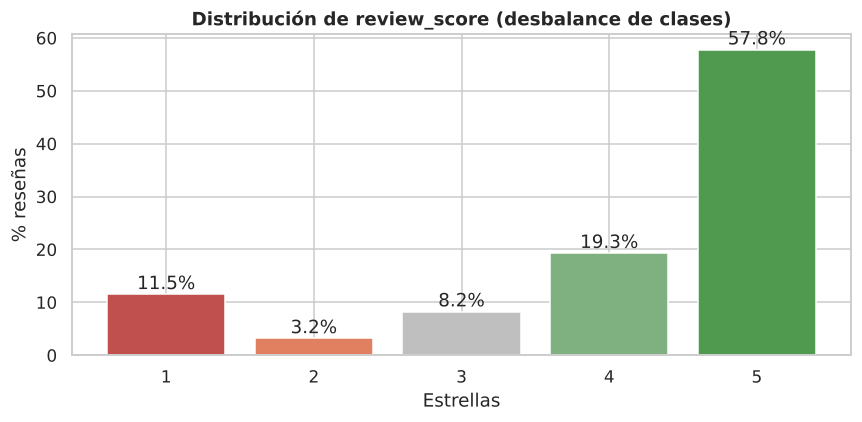

In [11]:
dist = rev.review_score.value_counts(normalize=True).sort_index() * 100
HALLAZGOS["review_score_%"] = dist.round(2).to_dict()
HALLAZGOS["review_negativa_%(<=2)"] = round(dist.loc[[1, 2]].sum(), 2)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#c0504d", "#e08060", "#bfbfbf", "#7fb07f", "#4f9a4f"]
ax.bar(dist.index.astype(str), dist.values, color=colors)
for i, v in enumerate(dist.values): ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set(title="Distribución de review_score (desbalance de clases)", xlabel="Estrellas", ylabel="% reseñas")
savefig("e01_review_score")

## 5. Análisis exploratorio

### 5.1 Estado de los pedidos

In [12]:
st = o.order_status.value_counts(normalize=True) * 100
HALLAZGOS["order_status_%"] = st.round(2).to_dict()
st.to_frame("%")

,%
order_status,
delivered,97.02
shipped,1.11
canceled,0.63
unavailable,0.61
invoiced,0.32
processing,0.30
created,0.01
approved,0.00


### 5.2 Estacionalidad y tendencia de ventas (insumo para series temporales)

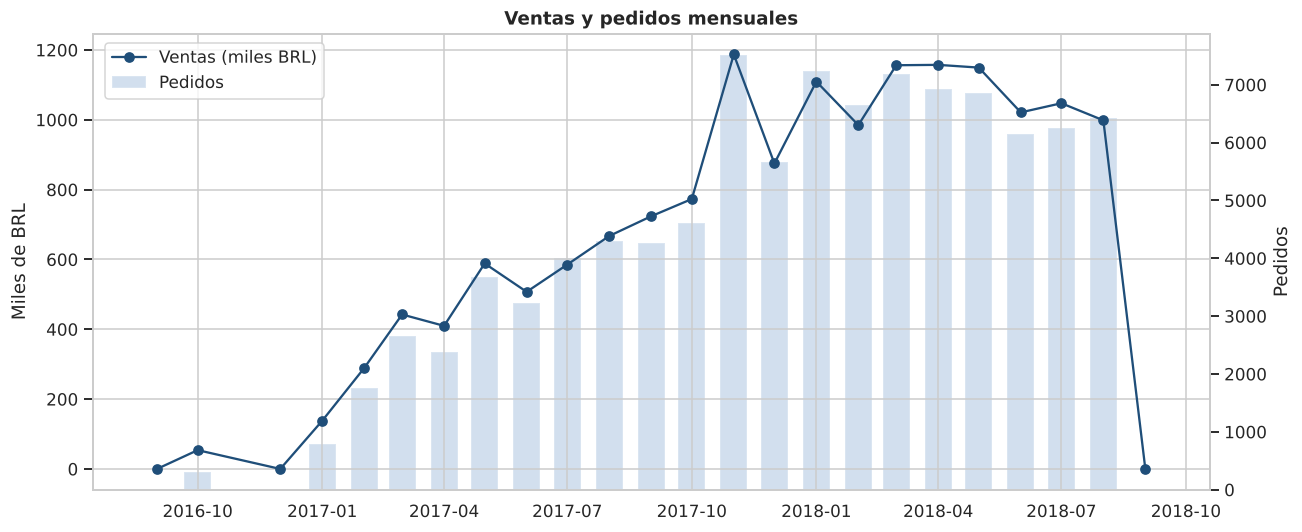

Días con más pedidos:
 order_purchase_timestamp
2017-11-24    1176
2017-11-25     499
2017-11-27     403
2017-11-26     389
2017-11-28     379
Name: order_id, dtype: int64


In [13]:
v = df[df.order_status != "canceled"]
mensual = v.groupby("mes").agg(pedidos=("order_id", "count"), ventas_BRL=("payment_value", "sum"))
mensual.index = mensual.index.to_timestamp()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(mensual.index, mensual.ventas_BRL / 1e3, marker="o", color="#1f4e79", label="Ventas (miles BRL)")
ax2 = ax1.twinx(); ax2.bar(mensual.index, mensual.pedidos, width=20, alpha=.25, color="#4f81bd", label="Pedidos")
ax1.set(title="Ventas y pedidos mensuales", ylabel="Miles de BRL"); ax2.set_ylabel("Pedidos"); ax2.grid(False)
ax1.set_zorder(ax2.get_zorder() + 1); ax1.patch.set_visible(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92))
savefig("e02_ventas_mensuales")

diario = v.set_index("order_purchase_timestamp").resample("D").order_id.count()
top_dias = diario.sort_values(ascending=False).head(5)
HALLAZGOS["top_dias_pedidos"] = {str(k.date()): int(x) for k, x in top_dias.items()}
print("Días con más pedidos:\n", top_dias)

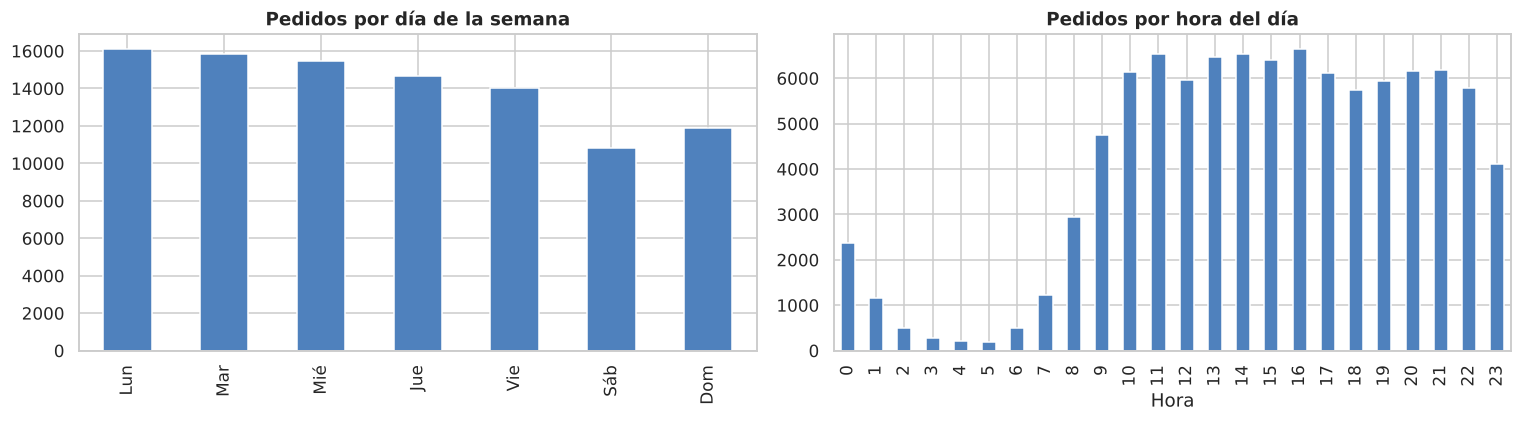

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
dow = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
v.order_purchase_timestamp.dt.dayofweek.value_counts().sort_index().set_axis(dow).plot.bar(ax=axes[0], color="#4f81bd")
axes[0].set(title="Pedidos por día de la semana", xlabel="")
v.order_purchase_timestamp.dt.hour.value_counts().sort_index().plot.bar(ax=axes[1], color="#4f81bd")
axes[1].set(title="Pedidos por hora del día", xlabel="Hora")
savefig("e03_patron_semanal_horario")

### 5.3 Pareto de categorías y tasa de reseñas negativas

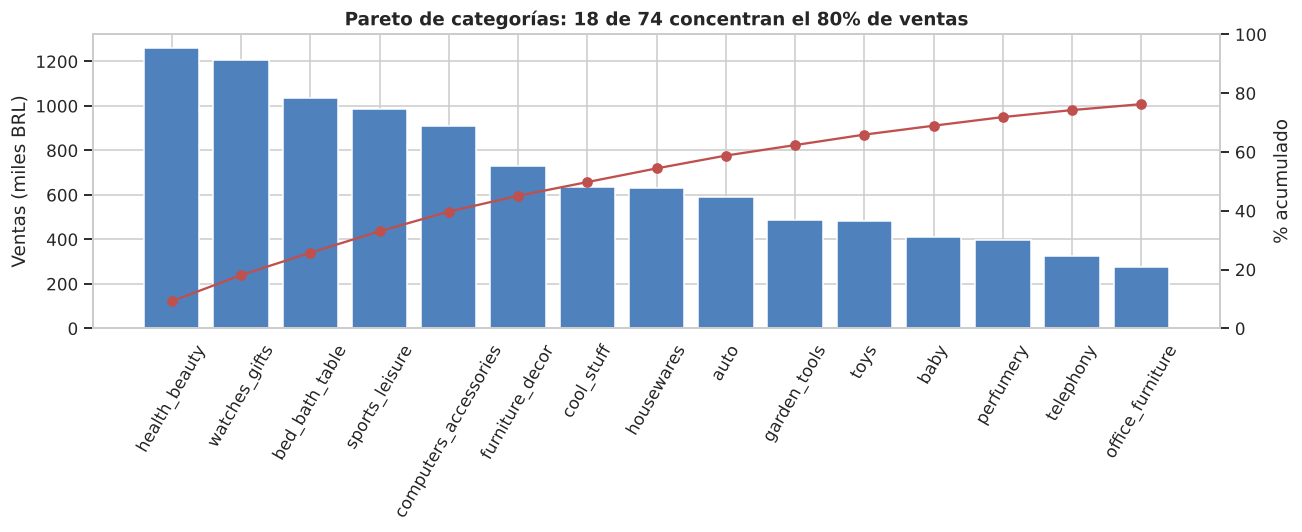

,items,ventas,%_acum_ventas,%_review_negativa
category,,,,
health_beauty,9670,"1,258,681.34",9.26,12.54
watches_gifts,5991,"1,205,005.68",18.13,15.05
bed_bath_table,11115,"1,036,988.68",25.76,16.48
sports_leisure,8641,"988,048.97",33.03,12.88
computers_accessories,7827,"911,954.32",39.74,16.04
furniture_decor,8334,"729,762.49",45.10,16.34
cool_stuff,3796,"635,290.85",49.78,12.24
housewares,6964,"632,248.66",54.43,12.99
auto,4235,"592,720.11",58.79,14.35


In [15]:
cat = items_full.groupby("category").agg(items=("order_item_id", "count"), ventas=("price", "sum"))
cat = cat.sort_values("ventas", ascending=False)
cat["%_acum_ventas"] = cat.ventas.cumsum() / cat.ventas.sum() * 100
neg_cat = df.groupby("categoria_principal").review_negativa.mean() * 100
cat["%_review_negativa"] = neg_cat.reindex(cat.index)
n80 = int((cat["%_acum_ventas"] <= 80).sum() + 1)
HALLAZGOS["n_categorias"] = int(len(cat)); HALLAZGOS["categorias_80%_ventas"] = n80
HALLAZGOS["top10_categorias"] = cat.head(10)[["ventas", "%_review_negativa"]].round(2).to_dict("index")

top = cat.head(15)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(top.index, top.ventas / 1e3, color="#4f81bd")
ax.set_ylabel("Ventas (miles BRL)"); ax.tick_params(axis="x", rotation=60)
ax2 = ax.twinx(); ax2.plot(top.index, top["%_acum_ventas"], color="#c0504d", marker="o"); ax2.set_ylim(0, 100)
ax2.set_ylabel("% acumulado"); ax2.grid(False)
ax.set_title(f"Pareto de categorías: {n80} de {len(cat)} concentran el 80% de ventas")
savefig("e04_pareto_categorias")
cat.head(15)

### 5.4 Logística vs satisfacción (hallazgo clave para clasificación y regresión)

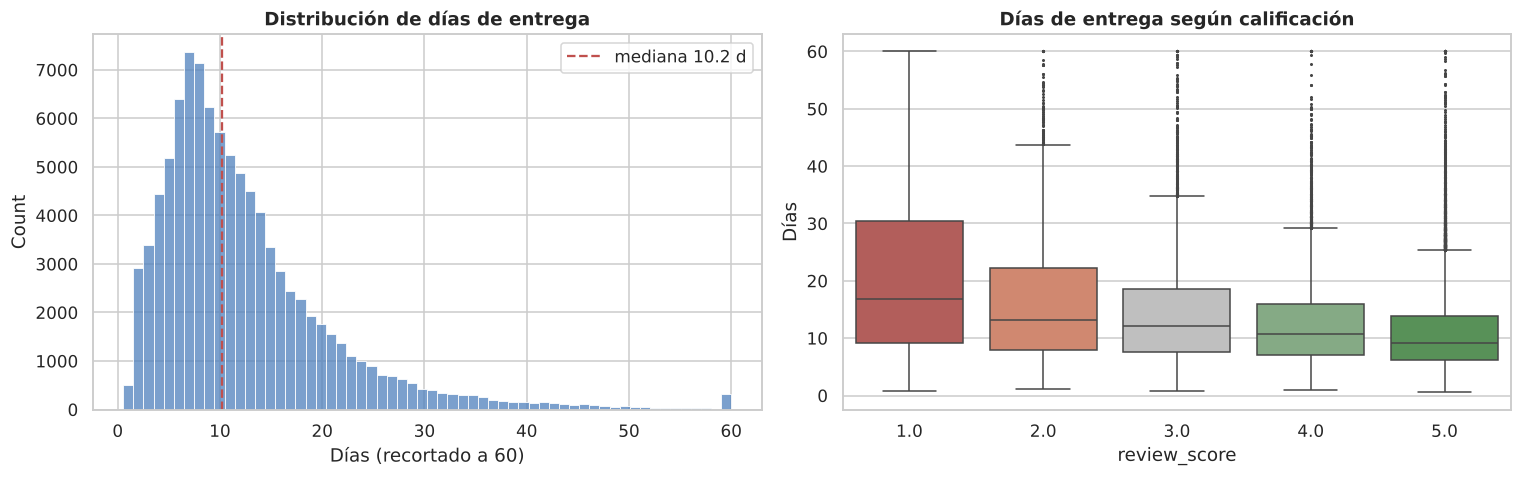

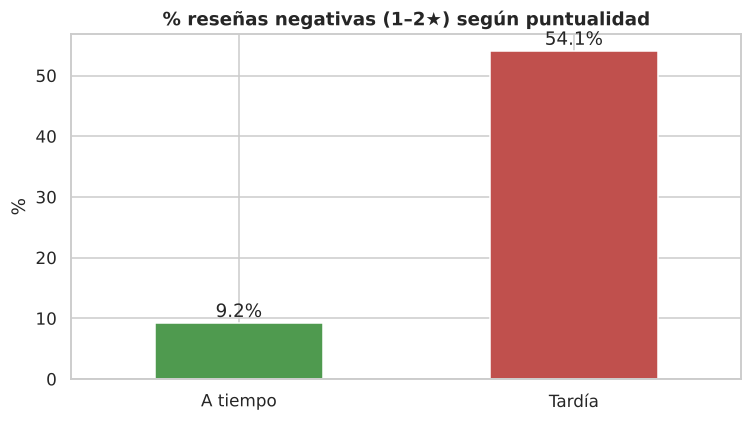

In [16]:
d = df[df.order_status == "delivered"].dropna(subset=["dias_entrega", "review_score"])
HALLAZGOS["dias_entrega_media"] = round(d.dias_entrega.mean(), 2)
HALLAZGOS["dias_entrega_mediana"] = round(d.dias_entrega.median(), 2)
HALLAZGOS["%_entregas_tardias"] = round(d.entrega_tardia.mean() * 100, 2)
HALLAZGOS["dias_estimacion_sobrante_media"] = round((-d.dias_retraso).mean(), 2)
# Baseline para el KPI de regresión: error de la estimación oficial de Olist
HALLAZGOS["MAE_estimacion_olist_dias"] = round((d.dias_estimados - d.dias_entrega).abs().mean(), 2)
neg_tardia = d.groupby("entrega_tardia").review_negativa.mean() * 100
HALLAZGOS["%_negativas_a_tiempo"] = round(neg_tardia.get(0, np.nan), 2)
HALLAZGOS["%_negativas_tardias"] = round(neg_tardia.get(1, np.nan), 2)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(d.dias_entrega.clip(upper=60), bins=60, ax=axes[0], color="#4f81bd")
axes[0].axvline(d.dias_entrega.median(), color="#c0504d", ls="--", label=f"mediana {d.dias_entrega.median():.1f} d")
axes[0].set(title="Distribución de días de entrega", xlabel="Días (recortado a 60)"); axes[0].legend()
sns.boxplot(data=d, x="review_score", y=d.dias_entrega.clip(upper=60), ax=axes[1], palette=colors, fliersize=1)
axes[1].set(title="Días de entrega según calificación", xlabel="review_score", ylabel="Días")
savefig("e05_entrega_vs_review")

fig, ax = plt.subplots(figsize=(7, 4))
(neg_tardia.rename({0: "A tiempo", 1: "Tardía"})).plot.bar(ax=ax, color=["#4f9a4f", "#c0504d"])
for i, val in enumerate(neg_tardia.values): ax.text(i, val + 1, f"{val:.1f}%", ha="center")
ax.set(title="% reseñas negativas (1–2★) según puntualidad", xlabel="", ylabel="%"); ax.tick_params(axis="x", rotation=0)
savefig("e06_negativas_por_retraso")

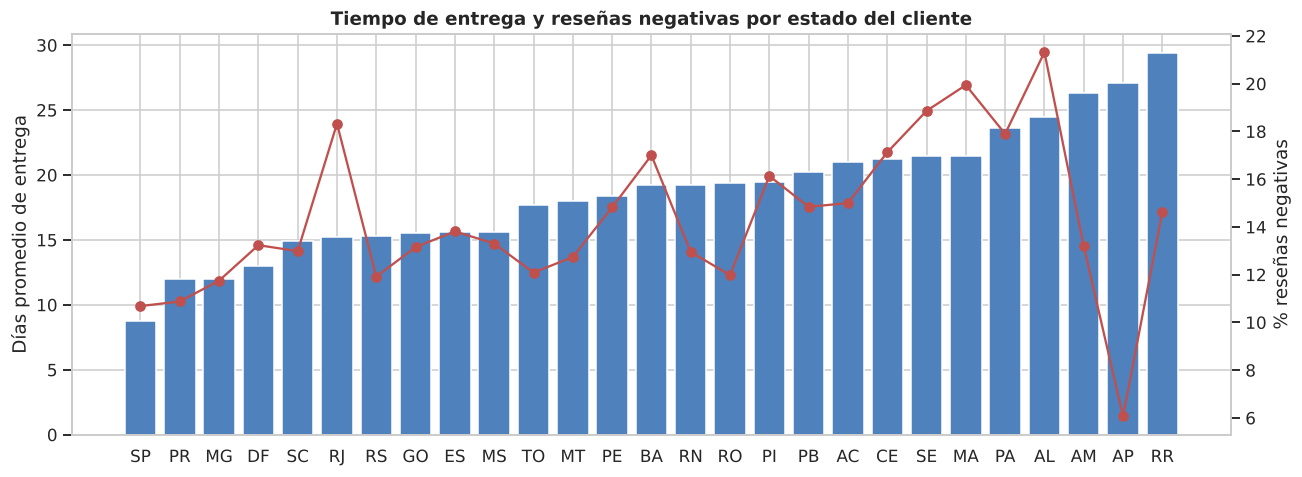

,pedidos,dias_entrega,pct_tardias,pct_negativas
customer_state,,,,
SP,40266,8.75,5.83,10.69
PR,4900,11.97,4.92,10.88
MG,11285,11.98,5.51,11.75
DF,2070,12.96,7.10,13.24
SC,3519,14.88,9.63,12.99
RJ,12211,15.24,13.29,18.33
RS,5326,15.28,7.10,11.92
GO,1946,15.56,7.97,13.16
ES,1969,15.61,11.88,13.81


In [17]:
est = d.groupby("customer_state").agg(pedidos=("order_id", "count"), dias_entrega=("dias_entrega", "mean"),
                                      pct_tardias=("entrega_tardia", "mean"), pct_negativas=("review_negativa", "mean"))
est[["pct_tardias", "pct_negativas"]] *= 100
est = est.sort_values("dias_entrega")
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(est.index, est.dias_entrega, color="#4f81bd"); ax.set_ylabel("Días promedio de entrega")
ax2 = ax.twinx(); ax2.plot(est.index, est.pct_negativas, color="#c0504d", marker="o"); ax2.set_ylabel("% reseñas negativas"); ax2.grid(False)
ax.set_title("Tiempo de entrega y reseñas negativas por estado del cliente")
savefig("e07_entrega_por_estado")
est

### 5.5 Clientes: recompra (crítico para RFM y retención)

In [18]:
compras = df[df.order_status != "canceled"].groupby("customer_unique_id").order_id.nunique()
HALLAZGOS["clientes_unicos"] = int(compras.size)
HALLAZGOS["%_clientes_recompra"] = round((compras > 1).mean() * 100, 2)
print(compras.value_counts().sort_index().head(8).to_frame("n_clientes"))
print(f"\n% clientes con más de una compra: {(compras > 1).mean()*100:.2f}%")

          n_clientes
order_id            
1              92636
2               2688
3                187
4                 30
5                  8
6                  6
7                  3
9                  1

% clientes con más de una compra: 3.06%


### 5.6 Canasta: ¿hay base para reglas de asociación?

In [19]:
HALLAZGOS["%_pedidos_multi_item"] = round((items_agg.n_items > 1).mean() * 100, 2)
HALLAZGOS["%_pedidos_multi_producto"] = round((items_agg.n_productos > 1).mean() * 100, 2)
HALLAZGOS["%_pedidos_multi_categoria"] = round((items_agg.n_categorias > 1).mean() * 100, 2)
HALLAZGOS["n_pedidos_multi_categoria"] = int((items_agg.n_categorias > 1).sum())
pd.Series({k: HALLAZGOS[k] for k in ["%_pedidos_multi_item", "%_pedidos_multi_producto", "%_pedidos_multi_categoria"]}).to_frame("%")

,%
%_pedidos_multi_item,9.94
%_pedidos_multi_producto,3.28
%_pedidos_multi_categoria,0.80


### 5.7 Pagos

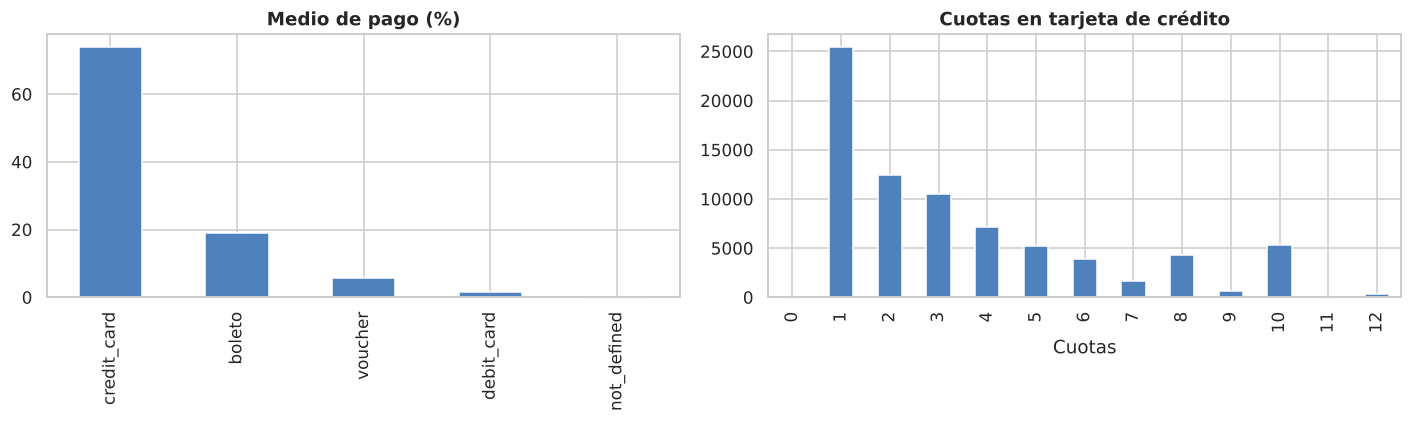

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pt = pay.payment_type.value_counts(normalize=True) * 100
pt.plot.bar(ax=axes[0], color="#4f81bd"); axes[0].set(title="Medio de pago (%)", xlabel="")
pay.loc[pay.payment_type == "credit_card", "payment_installments"].clip(upper=12).value_counts().sort_index().plot.bar(ax=axes[1], color="#4f81bd")
axes[1].set(title="Cuotas en tarjeta de crédito", xlabel="Cuotas")
savefig("e08_pagos")
HALLAZGOS["payment_type_%"] = pt.round(2).to_dict()
HALLAZGOS["ticket_promedio_BRL"] = round(df.loc[df.order_status != "canceled", "payment_value"].mean(), 2)

### 5.8 Comentarios (insumo para minería de textos)

In [21]:
txt = rev.review_comment_message.dropna().astype(str)
HALLAZGOS["%_reseñas_con_comentario"] = round(rev.review_comment_message.notna().mean() * 100, 2)
HALLAZGOS["palabras_por_comentario_mediana"] = int(txt.str.split().str.len().median())
com_por_score = rev.assign(con=rev.review_comment_message.notna()).groupby("review_score").con.mean() * 100
HALLAZGOS["%_con_comentario_por_score"] = com_por_score.round(2).to_dict()

import re
from collections import Counter
STOP_PT = set(("a o e de da do das dos em no na nos nas um uma uns umas que se por para com sem ao aos "
 "à às é foi ser são era mas mais muito já eu me meu minha você ele ela isso este esta esse essa "
 "como mesmo até ou também pelo pela ter tem tinha está estava estou the").split())
def top_words(series, n=15):
    words = Counter()
    for t in series:
        words.update(w for w in re.findall(r"[a-záéíóúâêôãõç]+", t.lower()) if w not in STOP_PT and len(w) > 2)
    return words.most_common(n)

neg_txt = rev.loc[rev.review_score <= 2, "review_comment_message"].dropna().astype(str)
pos_txt = rev.loc[rev.review_score >= 4, "review_comment_message"].dropna().astype(str)
tw = pd.DataFrame({"negativas (1–2★)": [f"{w} ({n})" for w, n in top_words(neg_txt)],
                   "positivas (4–5★)": [f"{w} ({n})" for w, n in top_words(pos_txt)]})
HALLAZGOS["top_palabras_negativas"] = [w for w, _ in top_words(neg_txt, 10)]
tw

,negativas (1–2★),positivas (4–5★)
0,não (7483),produto (10646)
1,produto (6189),prazo (7077)
2,recebi (3273),antes (5281)
3,comprei (1882),entrega (4633)
4,veio (1552),chegou (4016)
5,entrega (1412),bom (4008)
6,ainda (1401),recomendo (3873)
7,entregue (1329),bem (2697)
8,chegou (1180),entregue (2165)
9,nao (949),qualidade (2162)


### 5.9 Correlaciones entre variables numéricas del pedido

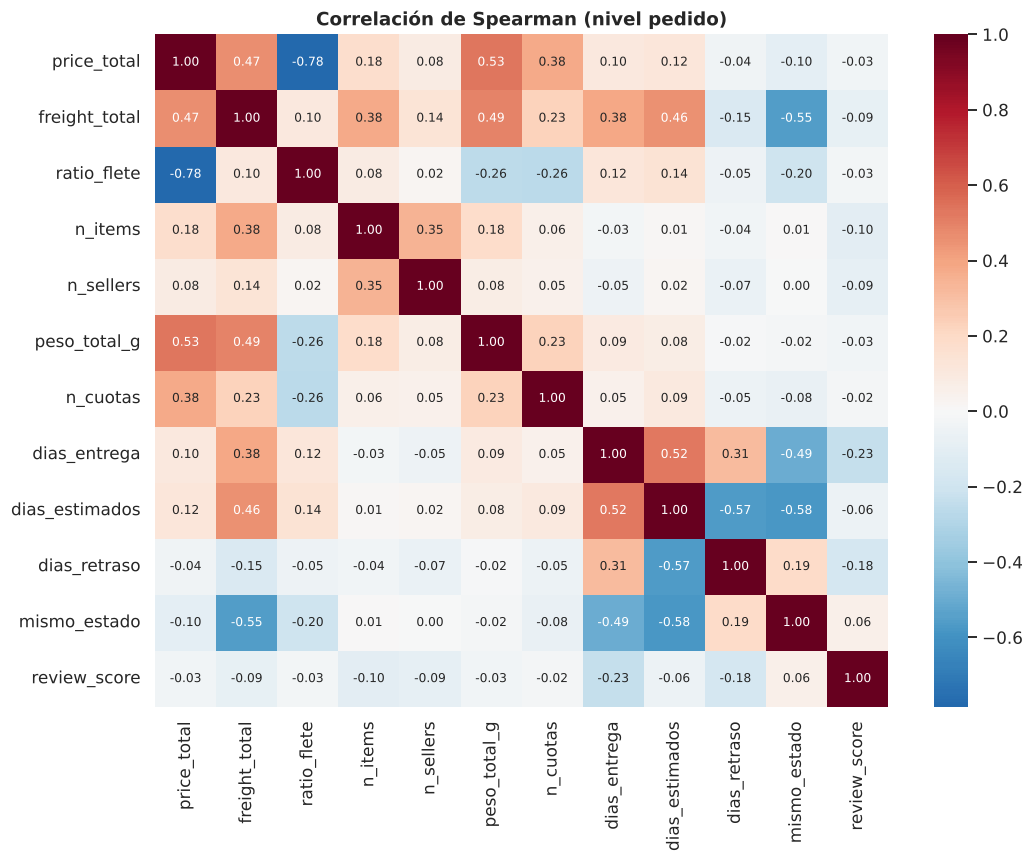

dias_entrega     -0.23
dias_retraso     -0.18
n_items          -0.10
n_sellers        -0.09
freight_total    -0.09
dias_estimados   -0.06
peso_total_g     -0.03
price_total      -0.03
ratio_flete      -0.03
n_cuotas         -0.02
mismo_estado      0.06
review_score      1.00
Name: review_score, dtype: float64

In [22]:
num = ["price_total", "freight_total", "ratio_flete", "n_items", "n_sellers", "peso_total_g", "n_cuotas",
       "dias_entrega", "dias_estimados", "dias_retraso", "mismo_estado", "review_score"]
corr = df[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlación de Spearman (nivel pedido)")
savefig("e09_correlaciones")
HALLAZGOS["corr_review_score"] = corr["review_score"].drop("review_score").round(3).sort_values().to_dict()
corr["review_score"].sort_values()

## 6. Hallazgos clave (exportados para la presentación)

In [23]:
def _clean(x):
    if isinstance(x, dict): return {str(k): _clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)): return [_clean(v) for v in x]
    if isinstance(x, (np.integer,)): return int(x)
    if isinstance(x, (np.floating,)): return None if np.isnan(x) else float(x)
    return x
with open(DOCS / "hallazgos_eda.json", "w", encoding="utf-8") as f:
    json.dump(_clean(HALLAZGOS), f, ensure_ascii=False, indent=2)

print(f"Pedidos: {HALLAZGOS['tablas']['orders']['filas']:,} | Periodo: {HALLAZGOS['periodo']}")
print(f"Reseñas negativas (1–2★): {HALLAZGOS['review_negativa_%(<=2)']}%")
print(f"Entrega mediana: {HALLAZGOS['dias_entrega_mediana']} días | tardías: {HALLAZGOS['%_entregas_tardias']}%")
print(f"% negativas a tiempo vs tardías: {HALLAZGOS['%_negativas_a_tiempo']}% vs {HALLAZGOS['%_negativas_tardias']}%")
print(f"MAE de la estimación oficial de Olist (baseline regresión): {HALLAZGOS['MAE_estimacion_olist_dias']} días")
print(f"Clientes con recompra: {HALLAZGOS['%_clientes_recompra']}%")
print(f"Pedidos multi-categoría (base para asociación): {HALLAZGOS['%_pedidos_multi_categoria']}%")
print(f"Reseñas con comentario: {HALLAZGOS['%_reseñas_con_comentario']}%")
print(f"\nFiguras en: {FIG.resolve()}")

Pedidos: 99,441 | Periodo: ['2016-09-04', '2018-10-17']
Reseñas negativas (1–2★): 14.69%
Entrega mediana: 10.21 días | tardías: 7.99%
% negativas a tiempo vs tardías: 9.22% vs 54.07%
MAE de la estimación oficial de Olist (baseline regresión): 12.73 días
Clientes con recompra: 3.06%
Pedidos multi-categoría (base para asociación): 0.8%
Reseñas con comentario: 41.3%

Figuras en: /home/claude/olist/docs/figures


### Conclusiones del EDA (datos reales)
1. **Desbalance:** 14.69% de reseñas son negativas (1–2★) y 57.78% son 5★. Por eso se evaluará con Recall, F1 y PR-AUC, y se entrenará con SMOTE o class_weight.
2. **La logística determina la satisfacción:** los pedidos tardíos tienen 54.07% de reseñas negativas, frente a 9.22% de los puntuales (5.9× más). El retraso es la variable clave del modelo de clasificación.
3. **La fecha prometida por Olist sobreestima la entrega en 11.22 días en promedio:** su MAE (12.73 días) es el baseline que debe superar el modelo de regresión. La entrega mediana es de 10.21 días y 7.99% de los pedidos llegan tarde.
4. **La recompra es muy baja (3.06% de 95,560 clientes únicos):** la F del RFM es casi constante, así que la segmentación se apoyará en Recencia, Monetario y CLV.
5. **Serie temporal:** el pico es el Black Friday (24-nov-2017, 1,176 pedidos en un día). 2016 y sep–oct 2018 están incompletos, por lo que se modelará de ene-2017 a ago-2018.
6. **Canastas:** solo 9.94% de los pedidos tiene más de un ítem, 3.28% más de un producto distinto y 0.8% más de una categoría (786 pedidos). La asociación se trabajará a nivel de producto y categoría, con soportes mínimos bajos.
7. **Textos:** 41.3% de las reseñas tienen comentario (mediana de 9 palabras). Las de 1★ comentan en un 76.55% y sus términos más frecuentes son de entrega: *não, recebi, entrega, chegou*.
8. **Calidad:** los nulos se explican por el estado del pedido o la ausencia de comentario. Hay 610 productos sin categoría, 261,831 filas duplicadas en geolocation y 1,359 pedidos con fechas fuera de orden. Los outliers de precio (7.48%) y flete (10.81%) son legítimos y se tratarán con transformación logarítmica.